# ITRI626: how each model is trained

This notebook shows how every model in the project is trained. It has one section per model. Each section has
the same four parts.

1. What the model is, why it is in the study, and why each setting was chosen.
2. The exact settings, checked against the saved run record.
3. The training code. It runs only when the model's switch in `TRAIN` is on.
4. The saved result, loaded from the run record.

| section | model | what is trained | in the course brief |
|---|---|---|---|
| 1 | **A** custom CNN | every weight, from random initialisation | yes |
| 2 | **B** ConvNeXt-Tiny | every weight, starting from ImageNet weights (fine-tuning) | yes |
| 3 | **C** SigLIP So400m ViT | one linear layer on frozen features (feature extraction) | yes |
| 4 | **Deployed** | a probe and a calibration temperature on frozen SigLIP features | no, the desktop app's main model |
| 5 | **Fast** | the Deployed head, refitted for a 308 px INT8 version of the encoder | no, the desktop app's fast model |

A, B and C are the three models that the brief asks for and the report compares. Sections 4 and 5 go beyond the
brief. They are the two models that the desktop app (`apps/gpui-demo`) ships.

**Nothing is retrained by default.** Every switch in `TRAIN` is off. The notebook then only loads the saved
records, which takes about a minute. A switch set to `True` retrains that model with the same functions,
configs and seed that produced the saved one. A retrained model goes to `runs/training_notebook/`, never over
`results/` or `exports/`.

**No training logic is copied here.** The cells call the project package `compclass` (`src/compclass/`) and the
experiment script `scripts/itri626_experiments.py`, which trained A, B and C.

**Test-set results are in another notebook.** This notebook never scores the test split.
`notebooks/ITRI626_three_models.ipynb` evaluates A, B, C and the deployed model on the 418 test images.

## 0. Setup

The first cell holds the one switch per model and the paths. Run the notebook from anywhere inside the
repository. Retraining needs the images in `data/v2/images/` (see the report's reproduction appendix) and, for A,
B and the SigLIP features, a GPU.

In [1]:
%matplotlib inline
import importlib.util
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, imported by timm, outside Jupyter widgets

TRAIN = {"A": False, "B": False, "C": False, "Deployed": False, "Fast": False}

sys.path.insert(0, str(Path.cwd()))  # notebooks/, for the evaluation notebook's helpers
import itri626_helpers as H

ROOT = H.ROOT
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)  # the configs and the manifest use paths relative to the repository root
SCRATCH = ROOT / "runs" / "training_notebook"  # git-ignored
FEATURE_CACHE = ROOT / "results" / "cache" / "features"  # compclass.features' default cache

# The script that trained A, B and C. Importing it reuses its model list, validation fold and head settings.
_spec = importlib.util.spec_from_file_location("itri626_experiments", ROOT / "scripts" / "itri626_experiments.py")
X = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(X)

pd.set_option("display.max_columns", 50, "display.width", 200, "display.precision", 4)
H.apply_figure_style()
print("repository root:", ROOT)
print("retraining:", [k for k, on in TRAIN.items() if on] or "nothing, every switch is off")

repository root: /home/vaper/Work/Prototypes/626-wt/notebook
retraining: nothing, every switch is off


In [2]:
def settings(cfg: dict) -> pd.DataFrame:
    """The model, train and aug sections of a compclass config as one row per setting."""
    rows = {f"{sec}.{k}": v for sec in ("model", "train", "aug") for k, v in cfg[sec].items()}
    return pd.DataFrame({"value": pd.Series(rows).astype(str)})


def show_curves(history: list[dict], best_epoch: int, title: str) -> pd.DataFrame:
    """Loss and accuracy per epoch, with the kept epoch marked; returns the kept epoch's row."""
    h = pd.DataFrame(history)
    e = h["epoch"] + 1
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(H.TEXTW, 2.4), layout="constrained")
    a1.plot(e, h["train_ce"], label="training")
    a1.plot(e, h["val_loss"], "--", color="black", label="validation")
    a1.set_ylabel("cross-entropy")
    a2.plot(e, h["train_acc"], label="training accuracy")
    a2.plot(e, h["val_acc"], "--", color="black", label="validation accuracy")
    a2.plot(e, h["val_macro_f1"], "-.", label="validation macro-F1")
    a2.set_ylim(0, 1.02)
    for a in (a1, a2):
        a.axvline(best_epoch + 1, color="#888888", lw=0.7)
        a.set_xlabel("epoch (grey line: kept epoch)")
        a.legend(fontsize=7)
    a1.set_title(title, fontsize=8)
    plt.show()
    keep = ["train_ce", "train_acc", "val_loss", "val_acc", "val_macro_f1"]
    return h.loc[[best_epoch], keep].rename(index={best_epoch: f"epoch {best_epoch + 1} of {len(h)}"})


display(pd.DataFrame({"this run": pd.Series(H.environment_report())}))
train_env = H.load_json(H.RES / "environment.json")
print("A, B and C were trained on", train_env["gpu"]["name"], "with torch", train_env["packages"]["torch"],
      "and timm", train_env["packages"]["timm"], "(results/itri626/environment.json)")

,this run
python,3.12.12
os,Linux-7.2.11-arch1-1-x86_64-with-glibc2.44
torch,2.11.0+cu128
torchvision,0.26.0+cu128
timm,1.0.30
open_clip_torch,3.3.0
scikit-learn,1.9.1
numpy,2.5.4
pandas,3.0.6
onnxruntime,1.31.0


A, B and C were trained on NVIDIA GeForce RTX 4060 Ti with torch 2.11.0+cu128 and timm 1.0.30 (results/itri626/environment.json)


### The fixed split

`data/v2/manifest.json` defines every split. Near-duplicate images share a cluster. `load_manifest` recomputes
the manifest's fingerprint and rejects the file if a cluster sits in two development folds or in a fold and the
test set. So no image, and no re-encoded copy of an image, appears on both sides of a split.

A, B and C train on development folds 1 to 4 and choose their epoch or weight decay on fold 0, the validation
split. Deployed and Fast use all five development folds. Their settings are checked by 5-fold grouped
cross-validation, and their final head is fitted on all development images. The cell checks the split against
the saved records.

In [3]:
from compclass.data import get_dev, get_fold, load_manifest

m = load_manifest(X.MANIFEST)
train_rows, val_rows = get_fold(m, X.FOLD)
dev_rows = get_dev(m)
saved_split = H.load_json(H.RES / "metrics.json")["split"]
assert m.fingerprint == saved_split["manifest_fingerprint"]
assert m.fingerprint == H.load_json(ROOT / "exports/final/fit_report.json")["manifest"]
assert m.fingerprint == H.load_json(ROOT / "exports/fast/fit_report.json")["manifest"]
assert X.FOLD == saved_split["val_fold"]
assert (len(train_rows), len(val_rows)) == (saved_split["train"], saved_split["val"])
assert not {r["cluster"] for r in train_rows} & {r["cluster"] for r in val_rows}

per_fold = pd.Series([r["fold"] for r in dev_rows]).value_counts().sort_index()
display(pd.DataFrame({
    "images": [len(train_rows), len(val_rows), len(dev_rows), saved_split["test"]],
    "used by": ["A, B, C (training)", "A, B, C (choosing the epoch)", "Deployed, Fast (5 folds)",
                "nobody here (evaluation notebook)"]},
    index=["train = folds 1-4", "validation = fold 0", "development = folds 0-4", "test (sealed)"]))
print("images per development fold:", {int(k): int(v) for k, v in per_fold.items()}, "| manifest fingerprint", m.fingerprint,
      "| split seed", saved_split["seed"], "|", len(m.classes), "classes")

,images,used by
train = folds 1-4,2010,"A, B, C (training)"
validation = fold 0,502,"A, B, C (choosing the epoch)"
development = folds 0-4,2512,"Deployed, Fast (5 folds)"
test (sealed),418,nobody here (evaluation notebook)


images per development fold: {0: 502, 1: 503, 2: 503, 3: 503, 4: 501} | manifest fingerprint 431315e87d2612cb | split seed 42 | 20 classes


## 1. Model A: custom CNN trained from scratch

**What it is.** A VGG-style network written for this project (`src/compclass/models/scratch_cnn.py`). A stride-2
stem convolution comes first. Four stages follow, each with two 3x3 convolution, BatchNorm and ReLU blocks (32, 64,
128 and 256 channels), with max-pooling between stages. Global average pooling, dropout 0.3 and one linear layer
give the 20 class scores. The network has 1,187,636 parameters, and all of them are trained.

**Why it is in the study.** It is the baseline without transfer learning. It shows what about 2,000 images can
teach a network that starts from random weights. B and C are measured against it.

**Transfer learning.** None. The weights start from He initialisation and see no other data.

**Settings and why.** The settings are `configs/scratch_cnn.yaml` on top of `configs/base.yaml`.

- Input 160 px. Evaluation resizes the short side to 183 px and cuts out the centre 160 px square.
- At most 120 epochs. AdamW with a peak learning rate of 2e-3, 5 warm-up epochs, then cosine decay to 0. Random
  weights need a high learning rate and many epochs. A pretrained network needs neither.
- Batch 64, fp16 mixed precision, gradient clipping at norm 1.0, seed 0.
- Augmentation on training batches only. A random resized crop keeps 35% to 100% of the image area with an aspect
  ratio of 0.75 to 1.33. Then a horizontal flip with probability 0.5, RandAugment (2 operations, magnitude 9) and
  colour jitter 0.2. The crop range is wider than B's (50% to 100%) because a network trained from scratch needs
  stronger regularisation. Web photos of parts vary in zoom, framing, lighting and white balance, so these changes
  are realistic. Vertical flips are off, because printed text and lighting in product photos have a natural "up".
- Weight decay 0.05, dropout 0.3 and label smoothing 0.1.

These recipes come from the project's earlier grouped 5-fold benchmark on the 2,512 development images
(`results/benchmark.csv`). The test images played no part.

**Overfitting control.** Augmentation, dropout, weight decay and label smoothing act during training. Early
stopping watches validation macro-F1 with a patience of 25 epochs.

**How the checkpoint is chosen.** After every epoch the training loop scores the validation split. It keeps the
weights of the epoch with the best validation macro-F1, which weights all 20 classes equally. The saved run used
all 120 epochs and kept epoch 106 (epochs counted from 1).

In [4]:
from compclass.config import config_hash, load_config

A_SPEC = X.MODELS["A_scratch_cnn"]
A_RUN = H.load_json(H.RES / "runs" / "A_scratch_cnn.json")
A_CFG = load_config(A_SPEC["config"], A_SPEC["sets"] + [f"output.runs_dir={SCRATCH}",
                                                        f"output.results={SCRATCH / 'runs.jsonl'}"])
SECTIONS = ("data", "model", "train", "aug")
assert {k: A_CFG[k] for k in SECTIONS} == {k: A_RUN["config"][k] for k in SECTIONS}
assert config_hash(A_CFG) == A_RUN["config_hash"]  # the hash ignores output paths and names the run directory
print(A_SPEC["config"], "+", A_SPEC["sets"] or "no overrides", "| fold", X.FOLD, "| config hash", A_RUN["config_hash"],
      "matches results/itri626/runs/A_scratch_cnn.json")
display(settings(A_CFG))

configs/scratch_cnn.yaml + no overrides | fold 0 | config hash 4e4c6e8f6cf3 matches results/itri626/runs/A_scratch_cnn.json


,value
model.key,scratch_cnn
model.pretrained,False
model.kwargs,"{'width': 32, 'dropout': 0.3}"
train.epochs,120
train.batch_size,64
train.accum_steps,1
train.lr,0.002
train.weight_decay,0.05
train.warmup_epochs,5
train.layer_decay,NaN


In [5]:
if TRAIN["A"]:
    from compclass import train as T

    A_NEW = T.run(A_CFG, X.FOLD)  # no test=True: the evaluation notebook scores the test split once
    print(f"retrained A: kept epoch {A_NEW['best_epoch'] + 1} of {A_NEW['epochs_run']}, validation macro-F1 "
          f"{A_NEW['macro_f1']:.4f} (saved run: epoch {A_RUN['best_epoch'] + 1}), checkpoint {A_NEW['run_dir']}/best.pt")
else:
    print('TRAIN["A"] is off: skipped. The saved run is shown below.')

TRAIN["A"] is off: skipped. The saved run is shown below.


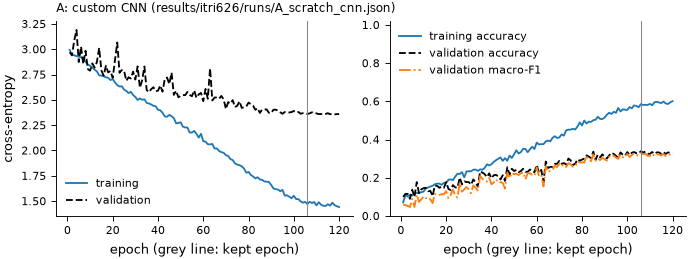

,train_ce,train_acc,val_loss,val_acc,val_macro_f1
epoch 106 of 120,1.4714,0.5857,2.3611,0.3386,0.3287


120 epochs in 147 s, peak GPU memory 430 MB, 1,187,636 trainable parameters


In [6]:
display(show_curves(A_RUN["history"], A_RUN["best_epoch"], "A: custom CNN (results/itri626/runs/A_scratch_cnn.json)"))
print(f"{A_RUN['epochs_run']} epochs in {A_RUN['train_time_s']:.0f} s, peak GPU memory {A_RUN['peak_vram_mb']} MB, "
      f"{A_RUN['trainable_params']:,} trainable parameters")

The training loss is still falling when the 120-epoch budget ends. The validation scores have levelled off since
about epoch 85. The gap between the two is a generalisation gap. About 2,000 images are not enough to learn
visual features from scratch. For A and B the training scores are measured on the augmented batches during each
epoch, not on the clean training images.

## 2. Model B: ConvNeXt-Tiny, fine-tuned

**What it is.** ConvNeXt (Liu et al., 2022) modernises the ResNet design with 7x7 depthwise convolutions,
inverted bottlenecks, LayerNorm and GELU. We use the Tiny variant with 27,835,508 parameters and the `timm`
weights `convnext_tiny.fb_in22k_ft_in1k`. They were pretrained on ImageNet-22k and then fine-tuned on
ImageNet-1k.

**Why it is in the study.** Fine-tuning an ImageNet network is the standard transfer-learning recipe for a small
dataset. ConvNeXt is the modern CNN family that the brief lists.

**Transfer learning.** Fine-tuning. The 1000-class ImageNet head is replaced by a new 20-class linear layer.
In the first epoch only this new layer trains, so its large early gradients do not disturb the pretrained
features. From the second epoch every layer trains. The learning-rate warm-up restarts when the backbone
unfreezes, so the pretrained layers never receive the peak learning rate on their first update. Layer-wise
learning-rate decay 0.8 gives each earlier layer group a smaller learning rate than the next one. Early layers
hold generic features and change less. Late layers hold task-specific features and change more.

**Settings and why.** The settings are `configs/convnext_tiny.yaml` on top of `configs/base.yaml`, with
`train.epochs=20 train.patience=6` from the experiment script (the main benchmark's recipe).

- Input 224 px with the ImageNet mean and standard deviation, as the weights were trained. Evaluation resizes the
  short side to 256 px and cuts out the centre 224 px square.
- At most 20 epochs. AdamW with a peak learning rate of 2e-4, 2 warm-up epochs, then cosine decay to 0. A
  pretrained network needs a small learning rate and few epochs.
- Batch 32, fp16 mixed precision, gradient clipping at norm 1.0, seed 0.
- Augmentation on training batches only. A random resized crop keeps 50% to 100% of the area with an aspect ratio
  of 0.75 to 1.33. Then a horizontal flip with probability 0.5 and RandAugment (2 operations, magnitude 9). The
  reasons are the same as for A.
- Weight decay 0.05, stochastic depth (drop path) 0.1 and label smoothing 0.1.

**Overfitting control.** A network with 28 million parameters fits 2,010 images quickly. Stochastic depth, weight
decay, label smoothing and augmentation slow this down. The short cosine schedule and early stopping on validation
macro-F1 (patience 6 epochs) stop it.

**How the checkpoint is chosen.** As for A, the epoch with the best validation macro-F1. The saved run trained all
20 epochs and kept epoch 19.

In [7]:
B_SPEC = X.MODELS["B_convnext_tiny"]
B_RUN = H.load_json(H.RES / "runs" / "B_convnext_tiny.json")
B_CFG = load_config(B_SPEC["config"], B_SPEC["sets"] + [f"output.runs_dir={SCRATCH}",
                                                        f"output.results={SCRATCH / 'runs.jsonl'}"])
assert {k: B_CFG[k] for k in SECTIONS} == {k: B_RUN["config"][k] for k in SECTIONS}
assert config_hash(B_CFG) == B_RUN["config_hash"]
print(B_SPEC["config"], "+", B_SPEC["sets"], "| fold", X.FOLD, "| config hash", B_RUN["config_hash"],
      "matches results/itri626/runs/B_convnext_tiny.json")
display(settings(B_CFG))

configs/convnext_tiny.yaml + ['train.epochs=20', 'train.patience=6'] | fold 0 | config hash bb9c72a49446 matches results/itri626/runs/B_convnext_tiny.json


,value
model.key,convnext_tiny
model.pretrained,True
model.kwargs,{'drop_path_rate': 0.1}
train.epochs,20
train.batch_size,32
train.accum_steps,1
train.lr,0.0002
train.weight_decay,0.05
train.warmup_epochs,2
train.layer_decay,0.8


In [8]:
if TRAIN["B"]:
    from compclass import train as T

    B_NEW = T.run(B_CFG, X.FOLD)  # downloads the timm ImageNet weights on first use
    print(f"retrained B: kept epoch {B_NEW['best_epoch'] + 1} of {B_NEW['epochs_run']}, validation macro-F1 "
          f"{B_NEW['macro_f1']:.4f} (saved run: epoch {B_RUN['best_epoch'] + 1}), checkpoint {B_NEW['run_dir']}/best.pt")
else:
    print('TRAIN["B"] is off: skipped. The saved run is shown below.')

TRAIN["B"] is off: skipped. The saved run is shown below.


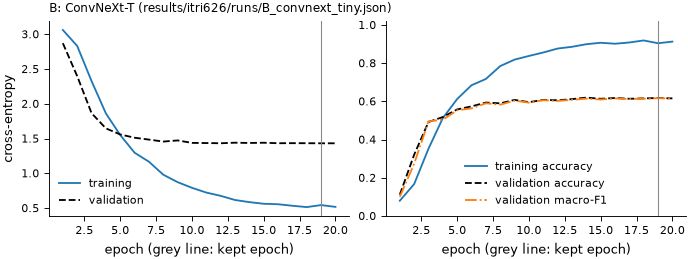

,train_ce,train_acc,val_loss,val_acc,val_macro_f1
epoch 19 of 20,0.5424,0.9042,1.4311,0.6175,0.6165


20 epochs in 120 s, peak GPU memory 2312 MB, 27,835,508 trainable parameters


In [9]:
display(show_curves(B_RUN["history"], B_RUN["best_epoch"], "B: ConvNeXt-T (results/itri626/runs/B_convnext_tiny.json)"))
print(f"{B_RUN['epochs_run']} epochs in {B_RUN['train_time_s']:.0f} s, peak GPU memory {B_RUN['peak_vram_mb']} MB, "
      f"{B_RUN['trainable_params']:,} trainable parameters")

B learns quickly from the pretrained features, and its validation accuracy levels off within about ten epochs.
Its training accuracy keeps rising while the validation loss stays flat. That is overfitting of a large network on a
small, noisy training set. The decaying learning rate and the kept best epoch stop it from getting worse.

## 3. Model C: frozen SigLIP So400m ViT with a linear head

**What it is.** A Vision Transformer cuts the image into patches and processes the patch tokens with
self-attention. SigLIP (Zhai et al., 2023) trains a ViT image encoder and a text encoder together on WebLI, a
web-scale collection of images and their text, with a pairwise sigmoid loss. We use its So400m/14 image encoder at
384x384 px (27 blocks, width 1152, 14 px patches; `timm` weights `vit_so400m_patch14_siglip_384.webli`). The
encoder is frozen. It turns each image into one 1152-number feature vector through its attention pooling. Only one
`nn.Linear(1152, 20)` layer is trained. It has 23,060 parameters.

**Why it is in the study.** It is the third family in the brief, the Vision Transformer. It is also the other end
of the transfer-learning range, because no encoder weight changes. It tests whether features learned from web
images and their captions already separate the 20 classes.

**Transfer learning.** Feature extraction, in three steps.

1. `compclass.features.extract_features` runs every development image once through the frozen encoder with the
   evaluation preprocessing and caches the features. The short side is resized to 427 px (bicubic), the centre
   384 px square is cut out, and the pixels are normalised with mean and standard deviation 0.5.
2. `compclass.linear_head` standardises the features with the mean and standard deviation of the training split
   only.
3. It trains the linear layer with cross-entropy and AdamW on mini-batches and logs every epoch like A and B.

**Settings and why.** The settings are `HEAD_KW` and `WD_GRID` in `scripts/itri626_experiments.py`.

- AdamW with a constant learning rate of 1e-3, batch 256, at most 200 epochs, seed 0. A linear layer on
  standardised features needs no learning-rate schedule.
- No augmentation and no label smoothing. Every feature comes from the fixed evaluation crop, which keeps the
  frozen-feature protocol simple and cheap. Training and validation losses are then directly comparable.
- Weight decay chosen on the validation split from 1e-4, 1e-3, 1e-2 and 1e-1. The three smallest values reach the
  same best validation macro-F1, because AdamW's decoupled decay changes little over a few dozen epochs at this
  learning rate. A rule fixed before the grid ran breaks ties by validation accuracy, then by the smaller value. It
  picks 1e-4. This is the only setting tuned for the study.

**Overfitting control.** The frozen encoder leaves one linear layer to fit 2,010 images. Weight decay and early
stopping on validation macro-F1 (patience 20 epochs) limit it further.

**How the head is chosen.** For each weight decay, the epoch with the best validation macro-F1 is kept, and ties
keep the earlier epoch. Then the weight decay with the best kept score wins. The saved head stopped after 34 epochs
and kept epoch 14.

In [10]:
C_RUN = H.load_json(H.RES / "runs" / "C_siglip_so400m_linear.json")
C_HEAD = dict(X.HEAD_KW)
saved = C_RUN["settings"]
assert C_HEAD == {"lr": saved["lr"], "epochs": saved["max_epochs"], "patience": saved["patience"],
                  "batch_size": saved["batch_size"], "seed": saved["seed"]}
assert [r["weight_decay"] for r in C_RUN["weight_decay_grid"]] == list(X.WD_GRID)
assert C_RUN["model"] == X.SIGLIP and json.loads(json.dumps(X.siglip_spec())) == C_RUN["preprocess"]
print("encoder", X.SIGLIP, "| preprocessing", C_RUN["preprocess"])
display(pd.DataFrame({"value": pd.Series({**C_HEAD, "weight_decay_grid": X.WD_GRID, "optimizer": saved["optimizer"],
                                          "schedule": saved["schedule"], "loss": saved["loss"],
                                          "feature_dim": C_RUN["feature_dim"]}).astype(str)}))

encoder siglip_so400m_384 | preprocessing {'input_size': 384, 'mean': [0.5, 0.5, 0.5], 'std': [0.5, 0.5, 0.5], 'interpolation': 'bicubic', 'crop_pct': 0.9, 'resize_short_side': 427}


,value
lr,0.001
epochs,200
patience,20
batch_size,256
seed,0
weight_decay_grid,"(0.0001, 0.001, 0.01, 0.1)"
optimizer,AdamW
schedule,constant
loss,cross-entropy
feature_dim,1152


In [11]:
if TRAIN["C"]:
    import torch
    from compclass.features import extract_features
    from compclass.linear_head import select_weight_decay

    F_dev = extract_features(X.SIGLIP, dev_rows, m, cache_dir=FEATURE_CACHE)  # cached after the first run
    pos = {r["id"]: i for i, r in enumerate(dev_rows)}

    def xy(rows):
        return F_dev[[pos[r["id"]] for r in rows]], np.array([m.class_to_idx[r["label"]] for r in rows])

    C_NEW, C_GRID_NEW = select_weight_decay(*xy(train_rows), *xy(val_rows), m.classes, grid=X.WD_GRID, **C_HEAD)
    (SCRATCH / "C_siglip_so400m_linear").mkdir(parents=True, exist_ok=True)
    torch.save(C_NEW.state(), SCRATCH / "C_siglip_so400m_linear" / "head.pt")
    display(pd.DataFrame(C_GRID_NEW))
    print(f"retrained C: weight decay {C_NEW.settings['weight_decay']:g}, kept epoch {C_NEW.best_epoch + 1} of "
          f"{len(C_NEW.history)}, validation macro-F1 {C_NEW.best_val_macro_f1:.4f} "
          f"(saved: {C_RUN['settings']['weight_decay']:g}, epoch {C_RUN['best_epoch'] + 1})")
else:
    print('TRAIN["C"] is off: skipped. The saved head is shown below.')

TRAIN["C"] is off: skipped. The saved head is shown below.


**Weight-decay grid on the validation split** (`results/itri626/head_grid.csv`, epochs from 0)

,weight_decay,best_epoch,epochs_run,val_macro_f1,val_acc,val_loss,selected
0,0.0001,13,34,0.8011,0.8028,0.7595,True
1,0.0010,13,34,0.8011,0.8028,0.7594,False
2,0.0100,13,34,0.8011,0.8028,0.7594,False
3,0.1000,20,41,0.7999,0.8008,0.7736,False


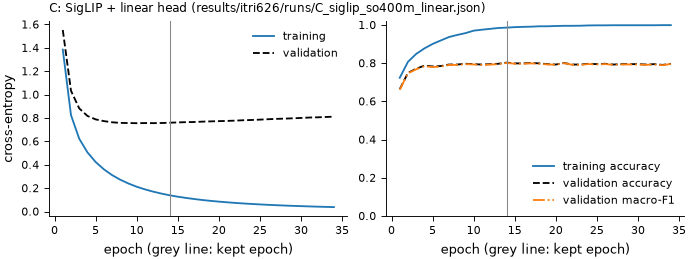

,train_ce,train_acc,val_loss,val_acc,val_macro_f1
epoch 14 of 34,0.139,0.9861,0.7595,0.8028,0.8011


23,060 trainable parameters; the 4 grid runs took 1.7 s on the CPU


In [12]:
display(Markdown("**Weight-decay grid on the validation split** (`results/itri626/head_grid.csv`, epochs from 0)"))
display(pd.read_csv(H.RES / "head_grid.csv"))
display(show_curves(C_RUN["history"], C_RUN["best_epoch"],
                    "C: SigLIP + linear head (results/itri626/runs/C_siglip_so400m_linear.json)"))
print(f"{C_RUN['trainable_params']:,} trainable parameters; the 4 grid runs took {C_RUN['train_time_s']} s on the CPU")

C's training curves are measured on the un-augmented training features after each epoch. The head reaches its
best validation macro-F1 early. After that the validation loss rises slowly while the training loss keeps falling.
Early stopping ends the run 20 epochs after the best epoch and keeps the best one.

## 4. Deployed: the desktop app's main model (beyond the brief)

This section and the next go beyond the course brief. They train the two models that the desktop app ships. The
report lists this model as reference row R2.

**What it is.** The frozen SigLIP So400m encoder at 384 px from model C, with two linear heads on its 1152-number
feature (`src/compclass/final.py`).

1. A linear probe. Scikit-learn standardises the feature and fits a multinomial logistic regression
   (`compclass.features.fit_probe`).
2. A zero-shot text head. SigLIP's text encoder embeds six prompt templates per class, such as "a photo of a
   {class}.", and averages them into one vector per class (`compclass.zeroshot`). The head scores an image by the
   cosine similarity between its feature and each class vector, multiplied by 50.

The model adds the two heads' log-probabilities, with weight 0.25 on the zero-shot head. It divides the sum by a
fitted temperature and applies softmax. When the top probability is below the abstain threshold, the app reports
the photo as unsure instead of naming a class.

**Why it is in the study.** It is the model behind the app. It extends C in four ways. The probe is fitted on all
2,512 development images instead of 2,010. The text head adds what SigLIP learned from captions. The temperature
makes the confidence values closer to the observed accuracy. The threshold lets the app decline photos it is unsure about.

**Transfer learning.** Feature extraction, as in C. No encoder weight changes. Only the probe (23,060 numbers) and
one temperature are fitted. The text head is not trained.

**Settings and why.**

- Zero-shot scale 50 and weight 0.25 were fixed before this fit, from an earlier out-of-fold analysis on the
  development folds (`results/phase1/fusion_ablation.csv`). They are not tuned here.
- The probe's regularisation strength C comes from 0.001, 0.003, 0.01, 0.1 and 1, chosen by grouped 3-fold
  cross-validation on macro-F1 inside the rows it is fitted on. The final fit chose C = 0.01.
- The temperature minimises the negative log-likelihood of the out-of-fold scores (Guo et al., 2017). It is 0.898,
  and it lowered the out-of-fold expected calibration error from 0.050 to 0.029.
- The abstain threshold is the smallest confidence, in steps of 0.05, at which the accepted out-of-fold predictions
  are at least 90% correct. It is 0.5.

**Overfitting control and selection.** `compclass.final.fit_head` runs grouped 5-fold cross-validation on the
2,512 development images. For each fold it fits the probe on the other four folds and scores the held-out fold
with the exact exported pipeline. These out-of-fold scores give the temperature, the threshold and the accuracy
estimate. Only then is the probe refitted on all 2,512 images. The recorded out-of-fold accuracy is 0.8264 and the
macro-F1 0.8256 (`exports/final/fit_report.json`). The probe alone reaches 0.8248, so on the development folds the
text head adds no more than noise. It was kept because it was fixed in advance and costs one 20x1152 matrix. On 407
later Wikimedia Commons photos it added 4.2 points (`EXPERIMENT_LOG.md`).

The project's speed harness later re-measured this model on the laptop at 0.8268 mean cross-validated accuracy
(`tools/speed/README.md`). The difference from 0.8264 is one image. On the laptop, fold 3's inner choice between
C = 0.01 and C = 0.1, whose macro-F1 differ by about 2e-4, falls the other way.

**Export.** `python -m compclass.final export` writes the ONNX graph and its parity checks into `exports/final/`.
This notebook does not run it, because it writes over the shipped model.

In [13]:
import inspect

from compclass import final as FINAL
from compclass.features import fit_probe
from compclass.zeroshot import TEMPLATES

D_REPORT = H.load_json(ROOT / "exports/final/fit_report.json")
D_PRE = H.load_json(ROOT / "exports/final/preprocess.json")
D_HEAD = dict(np.load(ROOT / "exports/final/head.npz"))
assert FINAL.KEY == D_PRE["model"] == X.SIGLIP
assert (FINAL.T_ZS, FINAL.W_ZS) == (D_REPORT["t_zs"], D_REPORT["w_zs"]) == (D_HEAD["t_zs"], D_HEAD["w_zs"])
assert D_REPORT["n_dev"] == len(dev_rows) and D_REPORT["final_C"] == D_HEAD["C"]
assert {k: D_PRE[k] for k in C_RUN["preprocess"]} == C_RUN["preprocess"]  # same encoder input as model C
display(pd.DataFrame({"value": pd.Series({
    "encoder": FINAL.KEY, "input_size": D_PRE["input_size"], "zero-shot scale (T_ZS)": FINAL.T_ZS,
    "zero-shot weight (W_ZS)": FINAL.W_ZS, "prompt templates": len(TEMPLATES),
    "probe C grid": inspect.signature(fit_probe).parameters["Cs"].default, "probe inner CV": "GroupKFold(3) on clusters",
    "outer CV": "5 grouped development folds", "abstain rule": "smallest threshold with OOF accepted accuracy >= 0.90",
}).astype(str)}))

,value
encoder,siglip_so400m_384
input_size,384
zero-shot scale (T_ZS),50.0
zero-shot weight (W_ZS),0.25
prompt templates,6
probe C grid,"(0.001, 0.003, 0.01, 0.1, 1.0)"
probe inner CV,GroupKFold(3) on clusters
outer CV,5 grouped development folds
abstain rule,smallest threshold with OOF accepted accuracy ...


In [14]:
if TRAIN["Deployed"]:
    import torch
    from compclass.features import extract_features

    F_dev = extract_features(FINAL.KEY, dev_rows, m, cache_dir=FEATURE_CACHE)
    W_text = FINAL.text_weights(m.classes, torch.device("cuda" if torch.cuda.is_available() else "cpu"))
    D_NEW, D_NEW_REPORT = FINAL.fit_head(F_dev, m, dev_rows, W_text)
    (SCRATCH / "deployed").mkdir(parents=True, exist_ok=True)
    np.savez(SCRATCH / "deployed" / "head.npz", **D_NEW)
    (SCRATCH / "deployed" / "fit_report.json").write_text(json.dumps(D_NEW_REPORT, indent=1))
    keys = ["oof_accuracy", "oof_macro_f1", "oof_probe_only_accuracy", "final_C", "temperature", "abstain_threshold"]
    display(pd.DataFrame({"retrained": {k: D_NEW_REPORT[k] for k in keys}, "saved": {k: D_REPORT[k] for k in keys}}))
    print("largest change in the probe weights:", float(np.abs(D_NEW["coef"] - D_HEAD["coef"]).max()))
else:
    print('TRAIN["Deployed"] is off: skipped. The saved fit is shown below.')

TRAIN["Deployed"] is off: skipped. The saved fit is shown below.


,oof_accuracy,oof_macro_f1,oof_probe_only_accuracy,oof_inscope_accuracy,final_C,temperature,ece_before,ece_after,abstain_threshold
Deployed (exports/final/fit_report.json),0.8264,0.8256,0.8248,0.8612,0.01,0.8977,0.0501,0.0295,0.5


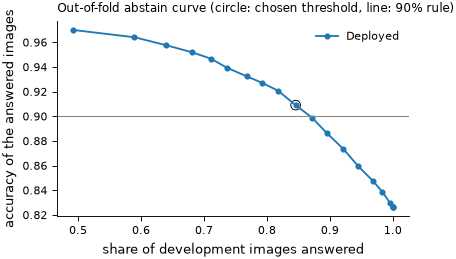

In [15]:
def fit_summary(rep: dict) -> pd.Series:
    keys = ["oof_accuracy", "oof_macro_f1", "oof_probe_only_accuracy", "oof_inscope_accuracy", "final_C",
            "temperature", "ece_before", "ece_after", "abstain_threshold"]
    return pd.Series({k: rep[k] for k in keys})


def show_abstain(reports: dict) -> None:
    fig, ax = plt.subplots(figsize=(H.TEXTW * 0.6, 2.4), layout="constrained")
    for name, rep in reports.items():
        t = pd.DataFrame(rep["abstain_table"])
        ax.plot(t["coverage"], t["accepted_acc"], marker=".", label=name)
        kept = t[t["threshold"] == rep["abstain_threshold"]].iloc[0]
        ax.scatter(kept["coverage"], kept["accepted_acc"], s=40, facecolors="none", edgecolors="black")
    ax.axhline(0.90, color="#888888", lw=0.7)
    ax.set_xlabel("share of development images answered")
    ax.set_ylabel("accuracy of the answered images")
    ax.set_title("Out-of-fold abstain curve (circle: chosen threshold, line: 90% rule)", fontsize=8)
    ax.legend(fontsize=7)
    plt.show()


display(fit_summary(D_REPORT).to_frame("Deployed (exports/final/fit_report.json)").T)
show_abstain({"Deployed": D_REPORT})

## 5. Fast: the desktop app's fast model (beyond the brief)

**What it is.** The deployed model made 9.2 times faster on the laptop's RTX 3060 GPU. Three things change. The
input is 308 px instead of 384 px. The encoder runs in INT8 under TensorRT. The heads are refitted on the features
of this new encoder. The encoder keeps the frozen SigLIP weights, and nothing in it is retrained.

**Why it is in the study.** It is the app's default model. In the project's speed harness the deployed model takes
109.1 ms per image at batch 1 on the laptop GPU, and Fast takes 11.9 ms. Both reach 0.8268 mean 5-fold
cross-validated accuracy on the development images.

**How exports/fast was produced.** Every step used development images or a separate calibration pool. The test
split and the web holdout were not used.

1. **Lower resolution.** `tools/tokens/build.py tokens_res308_trtfp16` edits the deployed encoder's ONNX graph.
   308 px gives a 22x22 grid of 14 px patches, so 484 tokens instead of 729. The 27x27 position embedding is
   resampled to 22x22 with bicubic interpolation. No weight is trained.
2. **INT8 quantisation.** `tools/compose/build.sh start` runs `tools/compose/remote_build.sh` on the GPU PC.
   - `tools/quant/candidate.py static1` fixes the batch size at 1.
   - `tools/quant/calib_stats.py` records activation statistics at the input of every weight matrix multiply, on
     512 calibration photos. They come from a separate pool of component photos (`tools/quant/calib_set.py`). None
     of them is a development or test image, or a near-copy of one.
   - `tools/quant/qdq.py smooth --alpha 0.5` applies SmoothQuant. It moves part of each activation's range into
     the following weights, which makes the activations easier to quantise. In floating point the change is exact.
   - `tools/quant/qdq.py qdq --calib max --calib-override mlp.fc2=p99.999` quantises all 112 weight matrix
     multiplies to INT8. Each weight output channel gets its own symmetric scale. Each activation gets one scale
     from its maximum. The inputs of every block's second MLP layer use the 99.999th percentile instead.
3. **Evaluation.** The frozen speed harness (`tools/speed/speed eval`, `time` and `compare`) runs all 2,512
   development images through the INT8 graph on TensorRT and keeps their features. It fits the deployed head
   recipe in 5-fold grouped cross-validation and times the graph against the deployed one.
4. **Head refit and export.** `tools/compose/export_fast.py` calls `compclass.final.fit_head` on those 2,512
   features with the deployed text vectors. It appends the fitted head to the INT8 graph as ONNX nodes and checks
   the graph's outputs against the head computed in numpy.

The training cell below runs step 4's head refit, the only step that fits parameters. Steps 1 to 3 change how the
frozen encoder computes, not what it learned. They need the 1.6 GB deployed graph, a TensorRT GPU and, for step 2,
the calibration pool, so the notebook lists them instead of running them.

**Transfer learning.** Feature extraction, as in Deployed.

**Settings and why.**

- 308 px. In the token study, 308 px kept the accuracy and 280 px lost too much (`tools/tokens/build.py`). A
  294 px INT8 version was about 10 times faster but lost 0.28 points, so it was not shipped (`EXPERIMENT_LOG.md`).
- SmoothQuant 0.5, INT8 on all 112 matrix multiplies and the 99.999th percentile for the second MLP layer are the
  best INT8 recipe of the quantisation study (`tools/quant/`), applied unchanged.
- Static batch 1. The app classifies one photo at a time, and batching gains only about 10% on this power-capped
  GPU (`EXPERIMENT_LOG.md`).
- The head recipe is the deployed one. The 308 px INT8 encoder gives slightly different features from the 384 px
  one, so the probe, temperature and threshold are fitted again on the new features. The refit chose C = 0.003,
  temperature 0.866 and threshold 0.5. The text vectors stay those of the deployed model.

**Overfitting control and selection.** As for Deployed, all settings come from out-of-fold scores of grouped 5-fold
cross-validation. The harness accepts a candidate only if its mean CV accuracy is at most 0.5 points below the
deployed model's and an exact McNemar test does not show it worse. Fast passed with a difference of 0.00 points.

In [16]:
FAST_REPORT = H.load_json(ROOT / "exports/fast/fit_report.json")
FAST_PRE = H.load_json(ROOT / "exports/fast/preprocess.json")
FAST_RT = H.load_json(ROOT / "exports/fast/runtime.json")
FAST_HEAD = dict(np.load(ROOT / "exports/fast/head.npz"))
FAST_EMBEDDINGS = Path(FAST_REPORT["embeddings"])  # the harness features of this exact INT8 graph
assert FAST_PRE["model"] == FINAL.KEY and FAST_PRE["input_size"] == 308
assert FAST_PRE["resize_short_side"] == round(FAST_PRE["input_size"] / FAST_PRE["crop_pct"])
assert FAST_RT["provider"] == "TensorrtExecutionProvider" and FAST_RT["options"]["trt_int8_enable"]
assert FAST_RT["static_batch"] == 1
assert "smooth05" in FAST_REPORT["trunk_built_from"] and "INT8 QDQ on 112/112 GEMMs" in FAST_REPORT["trunk_built_from"]
assert "mlp.fc2 p99.999" in FAST_REPORT["trunk_built_from"]
assert (FAST_REPORT["t_zs"], FAST_REPORT["w_zs"]) == (FINAL.T_ZS, FINAL.W_ZS)
assert FAST_REPORT["n_dev"] == len(dev_rows)
assert np.array_equal(FAST_HEAD["W"], D_HEAD["W"])  # the deployed text vectors, unchanged
display(pd.DataFrame({"value": pd.Series({
    "encoder graph": FAST_REPORT["trunk_candidate"], "input_size": FAST_PRE["input_size"],
    "resize_short_side": FAST_PRE["resize_short_side"], "quantisation": FAST_REPORT["trunk_built_from"].split(" (")[1].split(";")[0],
    "runtime": f'{FAST_RT["provider"]}, int8 + fp16, static batch {FAST_RT["static_batch"]}',
    "head recipe": "compclass.final.fit_head (as Deployed)", "features": str(FAST_EMBEDDINGS),
    "exporter": FAST_REPORT["exporter"],
}).astype(str)}))

,value
encoder graph,compose_int8_res308
input_size,308
resize_short_side,342
quantisation,"INT8 QDQ on 112/112 GEMMs, act max, mlp.fc2 p9..."
runtime,"TensorrtExecutionProvider, int8 + fp16, static..."
head recipe,compclass.final.fit_head (as Deployed)
features,/home/vaper/Work/Prototypes/626-artifacts/harn...
exporter,tools/compose/export_fast.py @ 48c7814


In [17]:
if TRAIN["Fast"]:
    if not FAST_EMBEDDINGS.exists():
        raise FileNotFoundError(f"{FAST_EMBEDDINGS} is missing; run tools/speed/speed eval on the INT8 graph first")
    ids = np.load(FAST_EMBEDDINGS.with_name("flags.npz"))["ids"]
    assert np.array_equal(ids, [r["id"] for r in dev_rows]), "features must be in development-row order"
    FAST_NEW, FAST_NEW_REPORT = FINAL.fit_head(np.load(FAST_EMBEDDINGS), m, dev_rows, D_HEAD["W"])
    (SCRATCH / "fast").mkdir(parents=True, exist_ok=True)
    np.savez(SCRATCH / "fast" / "head.npz", **FAST_NEW)
    (SCRATCH / "fast" / "fit_report.json").write_text(json.dumps(FAST_NEW_REPORT, indent=1))
    keys = ["oof_accuracy", "oof_macro_f1", "oof_probe_only_accuracy", "final_C", "temperature", "abstain_threshold"]
    display(pd.DataFrame({"retrained": {k: FAST_NEW_REPORT[k] for k in keys},
                          "saved": {k: FAST_REPORT[k] for k in keys}}))
    print("largest change in the probe weights:", float(np.abs(FAST_NEW["coef"] - FAST_HEAD["coef"]).max()))
else:
    print('TRAIN["Fast"] is off: skipped. The saved fit is shown below.')

TRAIN["Fast"] is off: skipped. The saved fit is shown below.


,oof_accuracy,oof_macro_f1,oof_probe_only_accuracy,oof_inscope_accuracy,final_C,temperature,ece_before,ece_after,abstain_threshold
Deployed,0.8264,0.8256,0.8248,0.8612,0.010,0.8977,0.0501,0.0295,0.5
Fast,0.8268,0.8262,0.8213,0.8567,0.003,0.8662,0.0649,0.0366,0.5


speed harness, Fast: 5-fold CV accuracy 0.8268 +/- 0.0141 (2026-10-31)
export parity on 314 development images: TensorRT graph vs numpy head, largest probability difference 0.0012, same top class on 100%


,batch-1 speed vs deployed,CV accuracy,change,verdict
candidate,,,,
"308 px, INT8 SmoothQuant, weights and activations (`compose_int8_res308`)",9.2x (11.9 ms),0.8268,0.00 pt,shipped as the app's Fast model


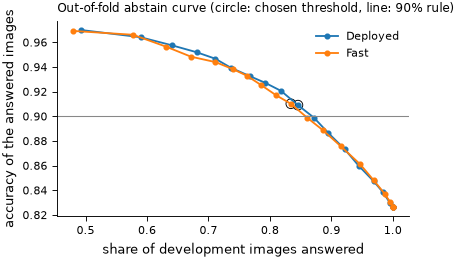

In [18]:
display(pd.DataFrame({"Deployed": fit_summary(D_REPORT), "Fast": fit_summary(FAST_REPORT)}).T)
ev, par = FAST_REPORT["harness_eval"], FAST_REPORT["parity"]
print(f"speed harness, Fast: 5-fold CV accuracy {ev['cv_acc_mean']:.4f} +/- {ev['cv_acc_sd']:.4f} ({ev['time_utc'][:10]})")
print(f"export parity on {par['runtime']['n']} development images: TensorRT graph vs numpy head, largest probability "
      f"difference {par['runtime']['max_abs_prob']:.4f}, same top class on {par['runtime']['argmax_agree']:.0%}")
row = next(ln for ln in (ROOT / "EXPERIMENT_LOG.md").read_text().splitlines() if "`compose_int8_res308`" in ln)
cells = [c.strip() for c in row.strip("|").split("|")]
display(pd.DataFrame([cells], columns=["candidate", "batch-1 speed vs deployed", "CV accuracy", "change",
                                       "verdict"]).set_index("candidate"))
show_abstain({"Deployed": D_REPORT, "Fast": FAST_REPORT})

## 6. Summary

A, B and C were each chosen on the 502 validation images, so their scores are validation scores at the kept
epoch. Deployed and Fast were checked by 5-fold grouped cross-validation on all 2,512 development images, so
their scores are out-of-fold scores. The two kinds of score use different images and are not directly comparable.

In [19]:
def val_at_best(run):
    h = run["history"][run["best_epoch"]]
    return h["val_acc"], h["val_macro_f1"]


rows = []
for key, run, what in (("A_scratch_cnn", A_RUN, "all weights, random start"),
                       ("B_convnext_tiny", B_RUN, "all weights, ImageNet start"),
                       ("C_siglip_so400m_linear", C_RUN, "linear layer on frozen features")):
    acc, f1 = val_at_best(run)
    rows.append({"model": H.SHORT[key], "trained": what, "trainable parameters": run["trainable_params"],
                 "training images": len(train_rows), "scored on": f"validation fold {X.FOLD} ({len(val_rows)})",
                 "accuracy": acc, "macro-F1": f1, "record": f"results/itri626/runs/{key}.json"})
for name, rep, head, path in (("Deployed", D_REPORT, D_HEAD, "exports/final/fit_report.json"),
                              ("Fast", FAST_REPORT, FAST_HEAD, "exports/fast/fit_report.json")):
    rows.append({"model": name, "trained": "probe + temperature on frozen features",
                 "trainable parameters": head["coef"].size + head["intercept"].size + 1,
                 "training images": rep["n_dev"], "scored on": "5-fold out-of-fold (2,512)",
                 "accuracy": rep["oof_accuracy"], "macro-F1": rep["oof_macro_f1"], "record": path})
display(pd.DataFrame(rows).set_index("model"))

,trained,trainable parameters,training images,scored on,accuracy,macro-F1,record
model,,,,,,,
A: scratch CNN,"all weights, random start",1187636,2010,validation fold 0 (502),0.3386,0.3287,results/itri626/runs/A_scratch_cnn.json
B: ConvNeXt-T (fine-tuned),"all weights, ImageNet start",27835508,2010,validation fold 0 (502),0.6175,0.6165,results/itri626/runs/B_convnext_tiny.json
C: SigLIP ViT (frozen + linear),linear layer on frozen features,23060,2010,validation fold 0 (502),0.8028,0.8011,results/itri626/runs/C_siglip_so400m_linear.json
Deployed,probe + temperature on frozen features,23061,2512,"5-fold out-of-fold (2,512)",0.8264,0.8256,exports/final/fit_report.json
Fast,probe + temperature on frozen features,23061,2512,"5-fold out-of-fold (2,512)",0.8268,0.8262,exports/fast/fit_report.json


**Test-set results.** `notebooks/ITRI626_three_models.ipynb` scores A, B, C and the deployed model (R2) once on
the 418 sealed test images and compares them. Fast has no test score. It was built after the test split had been
used for its one look, and the project's evaluation contract (`EXPERIMENT_LOG.md`) allows one look only.